# Late-onset preeclampsia: complete patient-level pipeline

Single notebook for the manuscript. It covers: loading the Jhee et al. S1 Data, reconstructing women from visit rows, cohort and outcome, trajectory features, leakage-controlled preprocessing, 12 classifiers plus 8 ensembles, one test evaluation with bootstrap CIs, calibration, alert burden per operating point, repeated random splits, SHAP, seeded LIME and DiCE stability, and all tables and figures.

Why a rebuild: in the original notebook `number` was a row counter (one unique value per row), so each visit was treated as a patient. This notebook groups rows into women first, then does everything at the woman level.

Set `DATA_PATH` in the first code cell. Use `SYNTHETIC = True` for a quick smoke test. Figures have no titles, as Journal of Medical Systems requires.

In [1]:
# ---------------------------------------------------------------- 1. Setup and configuration
import os, json, warnings
from itertools import combinations
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
from sklearn.ensemble import (AdaBoostClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier, RandomForestClassifier, StackingClassifier, VotingClassifier)
from sklearn.feature_selection import RFE, SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
warnings.filterwarnings("ignore")

try:
    import xgboost as xgb
except ImportError:
    xgb = None
try:
    import lightgbm as lgb
except ImportError:
    lgb = None
try:
    from catboost import CatBoostClassifier
except ImportError:
    CatBoostClassifier = None

# ---- configuration
DATA_PATH   = "/kaggle/input/datasets/suyaibalsifat/preeclampsia/preeclampsia.xlsx"   # S1 Data from Jhee et al. (sheet "Data")
SYNTHETIC   = False                  # True = generate a small fake file with the same layout (smoke test only)
FAST        = False                  # True = only 4 quick models (smoke test only)
OUT         = "results"
SEED        = 42
N_BOOT      = 1000
N_SPLITS_REPEAT = 0                  # repeated random splits (slow: re-tunes every model each time); try 2 or 3 for the final run
RUN_EXPLAIN = True                   # SHAP / LIME / DiCE (needs shap, lime, dice-ml)
os.makedirs(f"{OUT}/figs", exist_ok=True)
rng_global = np.random.RandomState(SEED)
trapz = getattr(np, "trapezoid", None) or np.trapz

In [2]:
# ---------------------------------------------------------------- 2. Variable definitions
TRAJ_VARS = ['AL','ALK','ALT','AST','BUN','CAL','CHOL','CR_SE','CRP','ESR','Gamma','Glu','Hb','K','Mg','PLT','Tbil',
             'Tco2','Tpro','Uric','Urine_AC','Urine_PC','WBC','SBP','DBP','PROTEIN','Weight_current']
STATIC_RENAME = {
 'T3_1_1':'Height','T3_1_2':'Weight_current','T3_1_3':'Weight_ref','T3_2_1':'Smoking','T3_2_2':'Alcohol',
 'T3_2_3':'Drug_allergy','T3_2_4':'Allergic_disease','T3_3_1':'Hypertension_history','T3_3_2':'Diabetes_history',
 'T3_3_3':'Hepatitis_history','T3_3_4':'Tuberculosis_history','T3_3_5':'Thyroid_disease_history','T3_3_6':'Surgery_history',
 'T3_3_7':'Blood_transfusion_history','T3_4_2':'Parity_normal_deliveries','T3_4_3':'Preterm_births','T3_4_4':'Number_of_children',
 'T3_4_5':'Stillbirths','T3_4_6':'Miscarriages','T3_5_1':'Family_hypertension','T3_5_2':'Family_diabetes','T3_5_3':'Family_hepatitis',
 'T3_5_4':'Family_tuberculosis','T3_5_5':'Family_cancer','T3_5_6':'Family_cerebrovascular_disease',
 'T3_5_7':'Family_preterm_birth_history','T3_5_8':'Prior_preeclampsia'}
# T3_1_2 changes between visits of the same woman (time-varying weight), so it is a trajectory variable, not a static one.
# T3_1_3 is constant within a woman. The English labels in the source file are uncertain; names here follow the observed behaviour.
STATIC_VARS = [v for v in STATIC_RENAME.values() if v != 'Weight_current']
ID_COLS = ['Height', 'Weight_ref', 'Parity_normal_deliveries', 'Preterm_births', 'Number_of_children', 'Miscarriages']  # constant within a woman (diagnose_grouping.py)
GA_VISIT, GA_DELIV, TARGET = 'PREG_WK', 'dur_week', 'TGT'

In [3]:
# ---------------------------------------------------------------- 3. Load data (or synthetic file) and reconstruct women
def load_raw(path):
    df = pd.read_excel(path, sheet_name='Data', header=0, skiprows=[1])
    df.columns = df.columns.astype(str).str.strip()
    if '(rev) dur_week' in df.columns and 'dur_week' in df.columns:
        df = df.drop(columns=['dur_week']).rename(columns={'(rev) dur_week': 'dur_week'})
    df = df.loc[:, ~df.columns.str.contains('^Unnamed', regex=True)].rename(columns=STATIC_RENAME)
    drop = [c for c in df.columns if c.startswith('CASE') or c.startswith('A003')]
    return df.drop(columns=drop, errors='ignore')

def synthetic_raw(n_women=400, seed=0):
    r = np.random.default_rng(seed); recs, num = [], 1
    for _ in range(n_women):
        n_vis = r.integers(1, 7); weeks = np.sort(r.choice(np.arange(8, 40), size=n_vis, replace=False))
        deliv = max(weeks.max(), r.integers(24, 41)); height, w0 = r.normal(161, 5), r.normal(60, 8)
        htn, fam = r.binomial(1, .05) + 1, r.binomial(1, .2) + 1; parity = int(r.integers(0, 3))
        pe = int(r.random() < 0.08 + 0.3 * (htn == 2))
        for wk in weeks:
            rec = {'number': num, 'dur_week': deliv, 'PREG_WK': wk, 'TGT': pe}
            for v in TRAJ_VARS:
                rec[v] = r.normal(100, 10) + (5 * pe if v in ('SBP', 'DBP') else 0) + 0.2 * wk
            rec.update({'Height': height, 'Weight_ref': w0, 'Weight_current': w0 + 0.3 * wk,
                        'Hypertension_history': htn, 'Family_hypertension': fam, 'Prior_preeclampsia': 1,
                        'Parity_normal_deliveries': parity})
            for s in STATIC_VARS + ID_COLS: rec.setdefault(s, 1)
            rec['D1AAA01'] = int(r.random() < .02); recs.append(rec); num += 1
    return pd.DataFrame(recs)

def reconstruct_women(df, id_cols=ID_COLS):
    # Rows are ordered by woman. A new woman starts when the visit week does not rise, or delivery week, outcome flag
    # or any identifier column (height, constant weight, obstetric counts) changes from the previous row.
    df = df.sort_values('number').reset_index(drop=True)
    cols = [GA_DELIV, TARGET] + [c for c in id_cols if c in df.columns]
    cur = df[cols].astype(float).to_numpy()
    same = np.r_[False, np.all(np.isclose(cur[1:], cur[:-1], equal_nan=True), axis=1)]
    ga = df[GA_VISIT].to_numpy(float); ga_up = np.r_[False, ga[1:] > ga[:-1]]
    df['patient_id'] = np.cumsum(~(same & ga_up))
    return df

raw = synthetic_raw() if SYNTHETIC else load_raw(DATA_PATH)
print("raw rows:", len(raw), "| unique `number` values:", raw['number'].nunique(), "(equal to rows => row counter, not patient ID)")
print(f"[delivery week + outcome + rising visit week only] women = {reconstruct_women(raw, id_cols=[])['patient_id'].nunique()}")
raw = reconstruct_women(raw)
per = raw.groupby('patient_id')[TARGET].max(); sizes = raw.groupby('patient_id').size()
print(f"[with identifier columns] rows={len(raw)}, women={raw['patient_id'].nunique()}, visits/woman={sizes.mean():.2f}, "
      f"single-visit women={(sizes == 1).mean():.1%}, max visits={sizes.max()}, TGT=1 in {int(per.sum())} women ({per.mean():.1%})")
print("Jhee et al. report 11,006 women (474 late-onset). This file contains more women than that; report the discrepancy in the paper.")

raw rows: 42965 | unique `number` values: 42965 (equal to rows => row counter, not patient ID)
[delivery week + outcome + rising visit week only] women = 23106
[with identifier columns] rows=42965, women=23503, visits/woman=1.83, single-visit women=54.9%, max visits=8, TGT=1 in 1446 women (6.2%)
Jhee et al. report 11,006 women (474 late-onset). This file contains more women than that; report the discrepancy in the paper.


In [4]:
# ---------------------------------------------------------------- 4. Cohort, outcome and patient-level trajectory features
def build_patient_matrix(df):
    for c in [GA_VISIT, GA_DELIV, TARGET] + TRAJ_VARS + STATIC_VARS:
        if c in df.columns: df[c] = pd.to_numeric(df[c], errors='coerce')
    info = df.groupby('patient_id').agg(delivery_ga=(GA_DELIV, 'max'), tgt=(TARGET, 'max'))
    info = info[info['delivery_ga'] >= 24]                                   # exclude delivery before 24 weeks
    info['late_onset_pe'] = ((info['tgt'] == 1) & (info['delivery_ga'] >= 34)).astype(int)
    pre = df[(df[GA_VISIT] <= 34) & df['patient_id'].isin(info.index)].copy() # predictors from visits at or before 34 weeks
    info = info.loc[info.index.isin(pre['patient_id'].unique())]
    rows = {}
    for pid, g in pre.sort_values(GA_VISIT).groupby('patient_id'):
        feat, t_all = {}, g[GA_VISIT].to_numpy(float)
        for v in TRAJ_VARS:
            if v not in g.columns: continue
            ok = g[v].notna().to_numpy(); y, t = g[v].to_numpy(float)[ok], t_all[ok]
            if len(y) == 0:   last = mean = np.nan; slope = cv = auc = 0.0
            elif len(y) == 1: last = mean = y[0]; slope = cv = auc = 0.0
            else:
                last, mean = y[-1], y.mean()
                slope = np.polyfit(t, y, 1)[0] if np.unique(t).size > 1 else 0.0
                cv = y.std(ddof=1) / mean if mean != 0 else 0.0
                auc = float(trapz(y, t))
            feat.update({f'{v}_last': last, f'{v}_slope': slope, f'{v}_cv': cv, f'{v}_mean': mean, f'{v}_auc': auc})
        for s in STATIC_VARS:
            if s in g.columns: feat[s] = g[s].iloc[0]
        rows[pid] = feat
    X = pd.DataFrame.from_dict(rows, orient='index')
    med = [c for c in df.columns if c.startswith(('D1', 'D2', 'D3'))]
    if med: X = X.join(pre.groupby('patient_id')[med].max().apply(pd.to_numeric, errors='coerce'))
    return X, info.loc[X.index, 'late_onset_pe'], pre

X, y, pre_visits = build_patient_matrix(raw)
print(f"Analytic cohort: {len(X)} women, {int(y.sum())} late-onset cases ({y.mean():.1%}); {X.shape[1]} candidate predictors")
slope_cols = [c for c in X.columns if c.endswith('_slope')]
print(f"Share of non-zero slopes: {(X[slope_cols] != 0).mean().mean():.1%}  (near 0% would mean trajectories are still degenerate)")
vis = pre_visits.groupby('patient_id').size()
print("Visits per woman before 34 weeks: median", vis.median(), "| share with a single visit", f"{(vis == 1).mean():.1%}")
print("Women with 2 or more visits (real trajectories):", int((vis >= 2).sum()), "| cases among them:", int(y.loc[vis[vis >= 2].index].sum()))

Analytic cohort: 11767 women, 317 late-onset cases (2.7%); 202 candidate predictors
Share of non-zero slopes: 56.5%  (near 0% would mean trajectories are still degenerate)
Visits per woman before 34 weeks: median 2.0 | share with a single visit 43.5%
Women with 2 or more visits (real trajectories): 6648 | cases among them: 131


In [5]:
# ---------------------------------------------------------------- 5. Split, then fit imputation, selection and scaling on training only
Xtr_raw, Xte_raw, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
cohort_tbl = pd.DataFrame({'Training': [len(ytr), f"{int(ytr.sum())} ({ytr.mean():.1%})"],
                           'Test': [len(yte), f"{int(yte.sum())} ({yte.mean():.1%})"]}, index=['Women, n', 'Late-onset PE, n (%)'])
print(cohort_tbl); cohort_tbl.to_csv(f"{OUT}/table_cohort.csv")

def fit_preprocess(Xtr_raw, ytr, seed=SEED):
    imp = SimpleImputer(strategy='median').fit(Xtr_raw)
    Xtr = pd.DataFrame(imp.transform(Xtr_raw), columns=Xtr_raw.columns, index=Xtr_raw.index)
    const = Xtr.columns[Xtr.std() == 0]; Xtr = Xtr.drop(columns=const)
    k = min(20, Xtr.shape[1])
    skb = SelectKBest(f_classif, k=k).fit(Xtr, ytr)
    rfe = RFE(RandomForestClassifier(n_estimators=100, random_state=seed, class_weight='balanced', n_jobs=-1), n_features_to_select=k).fit(Xtr, ytr)
    feats = Xtr.columns[skb.get_support() | rfe.support_].tolist()
    rank = pd.DataFrame({'Feature': feats, 'SelectKBest_F': pd.Series(skb.scores_, index=Xtr.columns)[feats].values,
                         'RFE_rank': pd.Series(rfe.ranking_, index=Xtr.columns)[feats].values})
    rank['Combined_rank'] = rank['SelectKBest_F'].rank(ascending=False) + rank['RFE_rank'].rank()
    sc = StandardScaler().fit(Xtr[feats])
    return imp, const, feats, sc, rank.sort_values('Combined_rank')

def apply_preprocess(Xraw, imp, const, feats, sc):
    Z = pd.DataFrame(imp.transform(Xraw), columns=Xraw.columns, index=Xraw.index).drop(columns=const)
    return pd.DataFrame(sc.transform(Z[feats]), columns=feats, index=Xraw.index), Z[feats]

imp, const, feats, sc, rank = fit_preprocess(Xtr_raw, ytr)
Xtr_s, Xtr_u = apply_preprocess(Xtr_raw, imp, const, feats, sc)
Xte_s, Xte_u = apply_preprocess(Xte_raw, imp, const, feats, sc)
rank.to_csv(f"{OUT}/table_selected_features.csv", index=False)
print(f"Selected {len(feats)} features. Trajectory descriptors kept:", [f for f in feats if f.endswith(('_slope', '_cv', '_auc'))])
print(rank.head(12).to_string(index=False))

                        Training       Test
Women, n                    9413       2354
Late-onset PE, n (%)  254 (2.7%)  63 (2.7%)
Selected 31 features. Trajectory descriptors kept: ['Hb_cv']
             Feature  SelectKBest_F  RFE_rank  Combined_rank
Hypertension_history     334.493781         1           11.5
            SBP_last     203.496366         1           12.5
            SBP_mean     200.091519         1           13.5
            DBP_mean     169.646395         1           14.5
            DBP_last     165.597266         1           15.5
            BUN_mean      44.021987         1           19.5
          CR_SE_mean      37.408941         1           24.5
          Weight_ref      33.897456         1           27.5
          CR_SE_last      27.209187         1           29.5
            ALK_mean      58.696760        36           31.0
            AST_mean      25.973654         1           31.5
              Height      10.989226         1           32.5


In [6]:
# ---------------------------------------------------------------- 6. Models and tuning (average precision, training CV only)
def make_models(ratio, fast):
    m = {
     'Logistic regression': (LogisticRegression(class_weight='balanced', max_iter=2000, random_state=SEED), {'C':[0.001,0.01,0.1,1,10,100],'solver':['lbfgs','saga']}),
     'Random forest': (RandomForestClassifier(class_weight='balanced', random_state=SEED, n_jobs=-1), {'n_estimators':[100,300,500],'max_depth':[5,10,20,None],'min_samples_leaf':[1,2,5]}),
     'Extra trees': (ExtraTreesClassifier(class_weight='balanced', random_state=SEED, n_jobs=-1), {'n_estimators':[100,300,500],'max_depth':[5,10,20,None],'min_samples_split':[2,5]}),
     'k-NN': (KNeighborsClassifier(), {'n_neighbors':[3,5,7,9,15],'weights':['uniform','distance'],'metric':['euclidean','manhattan']}),
     'Decision tree': (DecisionTreeClassifier(class_weight='balanced', random_state=SEED), {'max_depth':[3,5,10,20,None],'min_samples_split':[2,5,10]}),
     'Gradient boosting': (GradientBoostingClassifier(random_state=SEED), {'n_estimators':[100,200],'max_depth':[3,5,10],'learning_rate':[0.01,0.05,0.1]}),
     'Hist. gradient boosting': (HistGradientBoostingClassifier(class_weight='balanced', random_state=SEED), {'max_iter':[100,200],'max_depth':[3,5,10,None],'learning_rate':[0.01,0.05,0.1]}),
     'MLP': (MLPClassifier(max_iter=2000, random_state=SEED), {'hidden_layer_sizes':[(50,),(100,),(50,50)],'alpha':[0.0001,0.001,0.01]}),
     'Naive Bayes': (GaussianNB(), {}),
     'AdaBoost': (AdaBoostClassifier(random_state=SEED), {'n_estimators':[50,100,200],'learning_rate':[0.01,0.1,1.0]}),
    }
    if xgb is not None: m['XGBoost'] = (xgb.XGBClassifier(eval_metric='logloss', scale_pos_weight=ratio, random_state=SEED, n_jobs=-1), {'n_estimators':[100,200],'max_depth':[3,5,10],'learning_rate':[0.01,0.1]})
    if CatBoostClassifier is not None: m['CatBoost'] = (CatBoostClassifier(auto_class_weights='Balanced', verbose=0, random_state=SEED, thread_count=1), {'iterations':[100,200,500],'depth':[4,6,8,10],'learning_rate':[0.01,0.1]})
    if lgb is not None: m['LightGBM'] = (lgb.LGBMClassifier(class_weight='balanced', n_jobs=1, random_state=SEED, verbosity=-1), {'n_estimators':[50,100],'num_leaves':[15,31],'min_child_samples':[10,20]})
    if fast: m = {k: m[k] for k in ['Logistic regression', 'k-NN', 'Decision tree', 'Naive Bayes']}
    return m

def tune_all(Xs, ys, seed=SEED, verbose=True):
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)
    ratio = (ys == 0).sum() / (ys == 1).sum()
    trained, cv_ap, params = {}, {}, {}
    for name, (est, grid) in make_models(ratio, FAST).items():
        if grid:
            n_iter = min(20, int(np.prod([len(v) for v in grid.values()])))
            s = RandomizedSearchCV(est, grid, n_iter=n_iter, scoring='average_precision', cv=cv, n_jobs=-1, random_state=seed).fit(Xs, ys)
            trained[name], cv_ap[name], params[name] = s.best_estimator_, s.best_score_, s.best_params_
        else:
            cv_ap[name] = np.mean([average_precision_score(ys.iloc[v], est.fit(Xs.iloc[t], ys.iloc[t]).predict_proba(Xs.iloc[v])[:, 1]) for t, v in cv.split(Xs, ys)])
            trained[name], params[name] = est.fit(Xs, ys), {}
        if verbose: print(f"{name:26s} inner-CV AP {cv_ap[name]:.3f}  {params[name]}")
    return trained, cv_ap, params, cv

trained, cv_ap, params, cv = tune_all(Xtr_s, ytr)
json.dump({k: {a: (b.item() if hasattr(b, 'item') else b) for a, b in v.items()} for k, v in params.items()}, open(f"{OUT}/table_selected_hyperparameters.json", 'w'), indent=2, default=str)

Logistic regression        inner-CV AP 0.168  {'solver': 'saga', 'C': 0.01}
Random forest              inner-CV AP 0.314  {'n_estimators': 500, 'min_samples_leaf': 1, 'max_depth': None}
Extra trees                inner-CV AP 0.310  {'n_estimators': 500, 'min_samples_split': 5, 'max_depth': 10}
k-NN                       inner-CV AP 0.281  {'weights': 'distance', 'n_neighbors': 15, 'metric': 'manhattan'}
Decision tree              inner-CV AP 0.136  {'min_samples_split': 10, 'max_depth': None}
Gradient boosting          inner-CV AP 0.359  {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.05}
Hist. gradient boosting    inner-CV AP 0.400  {'max_iter': 200, 'max_depth': None, 'learning_rate': 0.05}
MLP                        inner-CV AP 0.310  {'hidden_layer_sizes': (50,), 'alpha': 0.01}
Naive Bayes                inner-CV AP 0.116  {}
AdaBoost                   inner-CV AP 0.245  {'n_estimators': 200, 'learning_rate': 1.0}
XGBoost                    inner-CV AP 0.356  {'n_estimator

In [7]:
# ---------------------------------------------------------------- 7. Ensembles from training-CV ranking (AdaBoost is excluded if degenerate)
def add_ensembles(trained, cv_ap, Xs, ys):
    base = [n for n in cv_ap if n != 'AdaBoost']
    top3 = sorted(base, key=cv_ap.get, reverse=True)[:3]
    print("Ensemble components (highest training-CV average precision):", top3)
    for k in (2, 3):
        for combo in combinations(top3, k):
            est = [(n.replace(' ', '_').replace('.', '').replace('-', '_'), trained[n]) for n in combo]
            nm = "+".join(combo)
            trained[f'Voting ({nm})'] = VotingClassifier(est, voting='soft').fit(Xs, ys)
            trained[f'Stacking ({nm})'] = StackingClassifier(est, final_estimator=LogisticRegression(class_weight='balanced', max_iter=2000), cv=5).fit(Xs, ys)
    return top3

top3 = add_ensembles(trained, cv_ap, Xtr_s, ytr)

Ensemble components (highest training-CV average precision): ['Hist. gradient boosting', 'LightGBM', 'CatBoost']


In [8]:
# ---------------------------------------------------------------- 8. One evaluation on the test partition, bootstrap CIs
def metrics(y_, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    tp = int(((pred == 1) & (y_ == 1)).sum()); fp = int(((pred == 1) & (y_ == 0)).sum())
    fn = int(((pred == 0) & (y_ == 1)).sum()); tn = int(((pred == 0) & (y_ == 0)).sum())
    return {'Accuracy': accuracy_score(y_, pred), 'Precision': precision_score(y_, pred, zero_division=0), 'Recall': recall_score(y_, pred, zero_division=0),
            'Specificity': tn / (tn + fp), 'F1': f1_score(y_, pred, zero_division=0), 'AUC-ROC': roc_auc_score(y_, prob),
            'AUC-PR': average_precision_score(y_, prob), 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn}

def bootstrap_ci(y_, prob, n_boot=N_BOOT, seed=SEED):
    r = np.random.RandomState(seed); keys = ['Accuracy','Precision','Recall','Specificity','F1','AUC-ROC','AUC-PR']
    acc = {k: [] for k in keys}
    for _ in range(n_boot):
        i = r.randint(0, len(y_), len(y_))
        if len(np.unique(y_[i])) < 2: continue
        mm = metrics(y_[i], prob[i]); [acc[k].append(mm[k]) for k in keys]
    return {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in acc.items()}

yt = yte.values; test_prob = {}; rows = []; ci_rows = []
for name, mdl in trained.items():
    p = mdl.predict_proba(Xte_s)[:, 1]; test_prob[name] = p
    rows.append({'Model': name, **metrics(yt, p)})
    ci = bootstrap_ci(yt, p); ci_rows.append({'Model': name, **{f'{m} 95% CI': f'{lo:.3f} to {hi:.3f}' for m, (lo, hi) in ci.items()}})
res = pd.DataFrame(rows).sort_values('AUC-ROC', ascending=False).reset_index(drop=True)
ci_df = pd.DataFrame(ci_rows).set_index('Model').loc[res['Model']].reset_index()
res.to_csv(f"{OUT}/table_test_performance.csv", index=False); ci_df.to_csv(f"{OUT}/table_test_bootstrap_ci.csv", index=False)
pd.DataFrame({'y_true': yt, **test_prob}).to_csv(f"{OUT}/test_predictions.csv", index=False)
print(res.round(3).drop(columns=['TP','FP','FN','TN']).to_string(index=False))
n_neg = int((yt == 0).sum()); print(f"\nAll-negative rule accuracy: {n_neg/len(yt):.3f}")

                                               Model  Accuracy  Precision  Recall  Specificity    F1  AUC-ROC  AUC-PR
                                       Random forest     0.974      0.600   0.048        0.999 0.088    0.871   0.235
                                             XGBoost     0.963      0.264   0.222        0.983 0.241    0.865   0.273
                          Voting (LightGBM+CatBoost)     0.962      0.297   0.302        0.980 0.299    0.859   0.275
                        Stacking (LightGBM+CatBoost)     0.906      0.174   0.667        0.913 0.275    0.859   0.277
  Voting (Hist. gradient boosting+LightGBM+CatBoost)     0.961      0.284   0.302        0.979 0.292    0.857   0.262
Stacking (Hist. gradient boosting+LightGBM+CatBoost)     0.901      0.165   0.667        0.907 0.265    0.857   0.258
           Voting (Hist. gradient boosting+LightGBM)     0.958      0.289   0.381        0.974 0.329    0.854   0.266
                                            LightGBM    

In [9]:
# ---------------------------------------------------------------- 9. Out-of-fold training predictions and univariate summary
oof = {'y_true': ytr.values}
for name, mdl in trained.items():
    oof[name] = cross_val_predict(mdl, Xtr_s, ytr, cv=cv, method='predict_proba')[:, 1]
pd.DataFrame(oof).to_csv(f"{OUT}/train_oof_predictions.csv", index=False)

uni = []
for c in feats:
    x = Xtr_u[c].values
    if x.std() == 0: continue
    r_, p_ = stats.pointbiserialr(ytr.values, x)
    uni.append({'Feature': c, 'Correlation': r_, 'p': p_, 'Mean, case': x[ytr.values == 1].mean(), 'Mean, non-case': x[ytr.values == 0].mean()})
uni = pd.DataFrame(uni).sort_values('Correlation', key=np.abs, ascending=False); uni.to_csv(f"{OUT}/table_univariate.csv", index=False)
print(uni.head(10).round(4).to_string(index=False))

             Feature  Correlation   p  Mean, case  Mean, non-case
Hypertension_history       0.1853 0.0      1.2205          1.0249
            SBP_last       0.1455 0.0    121.0951        112.7237
            SBP_mean       0.1443 0.0    119.8302        112.4647
            DBP_mean       0.1331 0.0     72.4597         67.6009
            DBP_last       0.1315 0.0     73.5995         67.9483
            ALK_mean       0.0787 0.0     51.3313         39.1014
 Family_hypertension       0.0710 0.0      1.3898          1.2098
  Prior_preeclampsia       0.0705 0.0      1.0079          1.0001
            BUN_mean       0.0682 0.0      5.7995          4.5813
           Uric_mean       0.0676 0.0      2.2034          1.7836


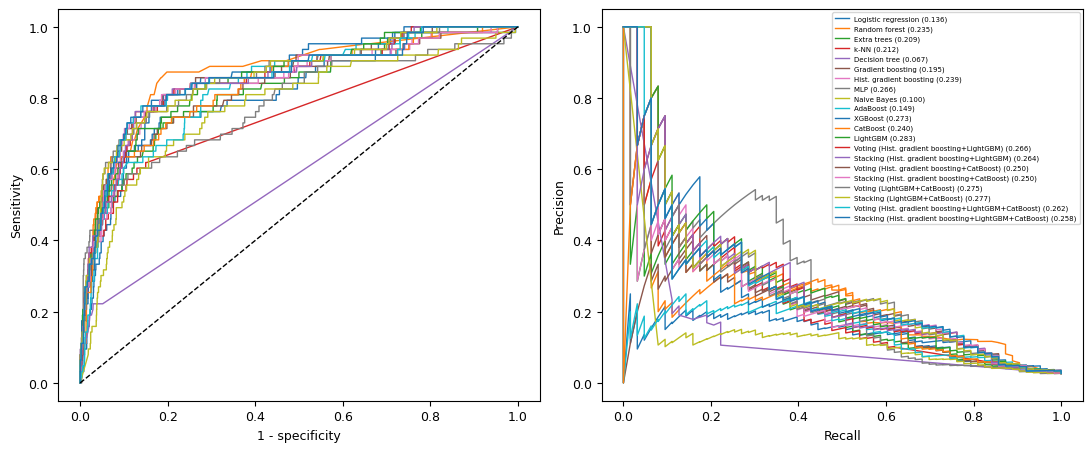

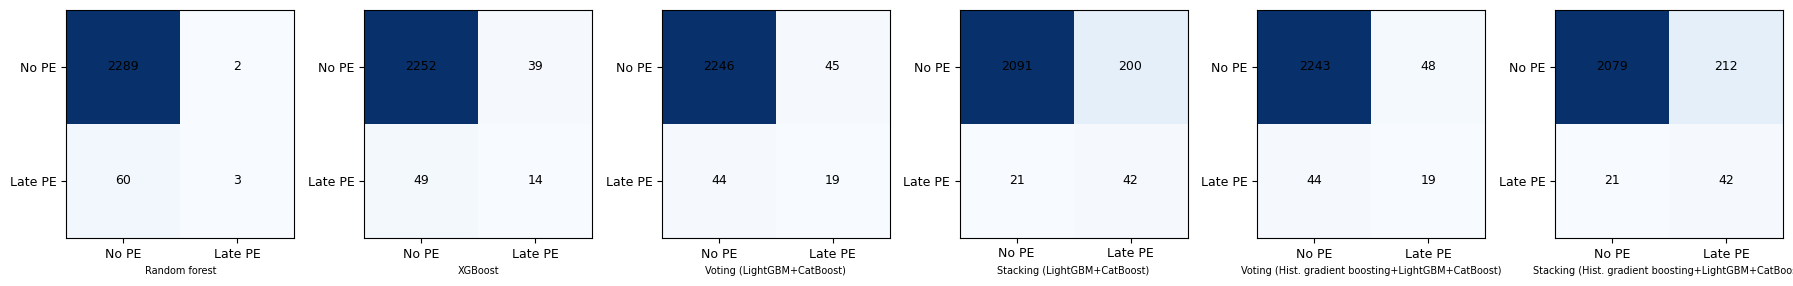

In [10]:
# ---------------------------------------------------------------- 10. Figures: ROC and precision-recall curves, confusion matrices (no titles)
plt.rcParams.update({'font.size': 9, 'font.family': 'sans-serif'})
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for name, p in test_prob.items():
    f, t, _ = roc_curve(yt, p); ax[0].plot(f, t, lw=1, label=f"{name} ({roc_auc_score(yt, p):.3f})")
    pr, rc, _ = precision_recall_curve(yt, p); ax[1].plot(rc, pr, lw=1, label=f"{name} ({average_precision_score(yt, p):.3f})")
ax[0].plot([0, 1], [0, 1], 'k--', lw=1); ax[0].set_xlabel('1 - specificity'); ax[0].set_ylabel('Sensitivity')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision')
ax[1].legend(fontsize=5, loc='upper right', ncol=1)
fig.tight_layout(); fig.savefig(f"{OUT}/figs/fig_roc_pr.png", dpi=300); plt.show()

best5 = res['Model'].head(6).tolist()
fig, axes = plt.subplots(1, len(best5), figsize=(3 * len(best5), 3))
for a, name in zip(np.atleast_1d(axes), best5):
    r_ = res.set_index('Model').loc[name]; cm = np.array([[r_['TN'], r_['FP']], [r_['FN'], r_['TP']]])
    a.imshow(cm, cmap='Blues'); a.set_xticks([0, 1], ['No PE', 'Late PE']); a.set_yticks([0, 1], ['No PE', 'Late PE'])
    for i in range(2):
        for j in range(2): a.text(j, i, int(cm[i, j]), ha='center', va='center')
    a.set_xlabel(name, fontsize=7)
fig.tight_layout(); fig.savefig(f"{OUT}/figs/fig_confusion_top.png", dpi=300); plt.show()

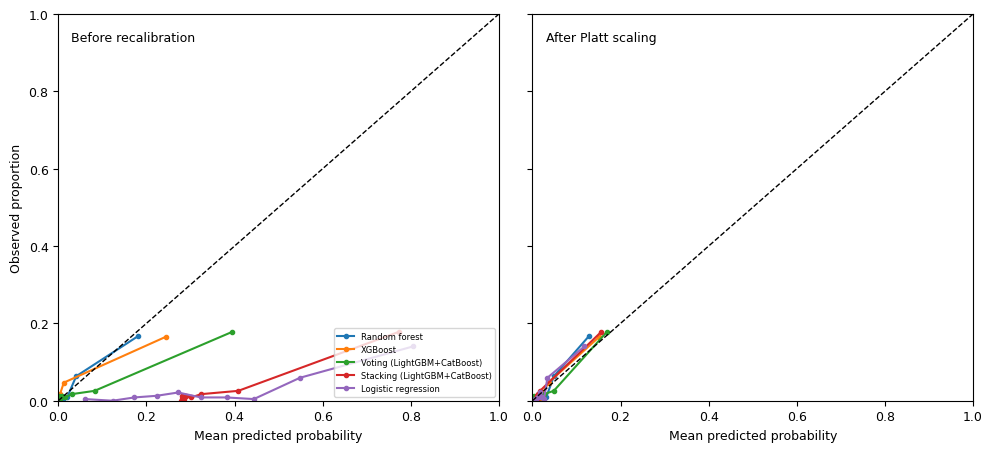

                       Model Version                  Brier                 Intercept                  Slope
               Random forest     Raw 0.023 (0.018 to 0.028)   0.034 (-0.295 to 0.304) 0.654 (0.398 to 0.936)
               Random forest   Platt 0.023 (0.018 to 0.028)   0.049 (-0.239 to 0.267) 1.013 (0.614 to 1.448)
                     XGBoost     Raw 0.027 (0.021 to 0.033)   0.022 (-0.521 to 0.497) 0.463 (0.393 to 0.539)
                     XGBoost   Platt 0.023 (0.017 to 0.028)   0.017 (-0.270 to 0.270) 1.008 (0.855 to 1.177)
  Voting (LightGBM+CatBoost)     Raw 0.030 (0.024 to 0.035) -1.122 (-1.490 to -0.792) 0.626 (0.509 to 0.763)
  Voting (LightGBM+CatBoost)   Platt 0.023 (0.017 to 0.028)  -0.115 (-0.396 to 0.128) 1.022 (0.830 to 1.247)
Stacking (LightGBM+CatBoost)     Raw 0.138 (0.132 to 0.145) -3.859 (-4.243 to -3.534) 0.767 (0.645 to 0.900)
Stacking (LightGBM+CatBoost)   Platt 0.024 (0.018 to 0.029)   0.026 (-0.293 to 0.301) 0.897 (0.754 to 1.054)
         Logistic r

In [11]:
# ---------------------------------------------------------------- 11. Calibration (before and after Platt scaling fitted on out-of-fold training predictions)
EPS = 1e-6
def logit(p): p = np.clip(p, EPS, 1 - EPS); return np.log(p / (1 - p))
def cal_slope(y_, p):
    return float(LogisticRegression(C=1e6, max_iter=1000).fit(logit(p).reshape(-1, 1), y_).coef_[0, 0])
def cal_intercept(y_, p):
    lp = logit(p); return float(minimize(lambda a: np.sum(np.logaddexp(0, a[0] + lp) - y_ * (a[0] + lp)), x0=[0.0], method='BFGS').x[0])
def platt_fit(y_, p):
    m = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p).reshape(-1, 1), y_); return lambda q: m.predict_proba(logit(q).reshape(-1, 1))[:, 1]
def cal_summary(y_, p, n_boot=N_BOOT, seed=SEED):
    r = np.random.RandomState(seed); st = {'Brier': brier_score_loss(y_, p), 'Intercept': cal_intercept(y_, p), 'Slope': cal_slope(y_, p)}
    bs = {k: [] for k in st}
    for _ in range(n_boot):
        i = r.randint(0, len(y_), len(y_))
        if y_[i].sum() == 0: continue
        bs['Brier'].append(brier_score_loss(y_[i], p[i])); bs['Intercept'].append(cal_intercept(y_[i], p[i])); bs['Slope'].append(cal_slope(y_[i], p[i]))
    return {k: f"{v:.3f} ({np.percentile(bs[k], 2.5):.3f} to {np.percentile(bs[k], 97.5):.3f})" for k, v in st.items()}

cal_models = res['Model'].head(4).tolist() + [m for m in res['Model'] if m.startswith('Stacking')][:1] + ['Logistic regression']
cal_models = list(dict.fromkeys(cal_models)); cal_rows = []
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
for name in cal_models:
    p_raw = test_prob[name]; p_pl = platt_fit(ytr.values, oof[name])(p_raw)
    for tag, p, a in (('Raw', p_raw, axes[0]), ('Platt', p_pl, axes[1])):
        cal_rows.append({'Model': name, 'Version': tag, **cal_summary(yt, p)})
        q = pd.qcut(p, q=10, duplicates='drop'); d = pd.DataFrame({'y': yt, 'p': p, 'b': q}).groupby('b', observed=True).agg(p=('p', 'mean'), y=('y', 'mean'))
        a.plot(d['p'], d['y'], marker='o', ms=3, label=name)
for a, t in zip(axes, ('Before recalibration', 'After Platt scaling')):
    a.plot([0, 1], [0, 1], 'k--', lw=1); a.set_xlabel('Mean predicted probability'); a.set_xlim(0, 1); a.set_ylim(0, 1); a.text(0.03, 0.93, t, transform=a.transAxes)
axes[0].set_ylabel('Observed proportion'); axes[0].legend(fontsize=6, loc='lower right')
fig.tight_layout(); fig.savefig(f"{OUT}/figs/fig_calibration.png", dpi=300); plt.show()
cal_df = pd.DataFrame(cal_rows); cal_df.to_csv(f"{OUT}/table_calibration.csv", index=False); print(cal_df.to_string(index=False))

In [12]:
# ---------------------------------------------------------------- 12. Operating points: alert burden at 0.5 and at thresholds set on TRAINING predictions
def flagged_table(names, thresholds):
    out = []
    for name in names:
        for thr in thresholds[name]:
            m = metrics(yt, test_prob[name], thr); fl = m['TP'] + m['FP']
            out.append({'Model': name, 'Threshold': round(float(thr), 4), 'Flagged, %': 100 * fl / len(yt), 'Cases detected': m['TP'], 'Cases missed': m['FN'],
                        'False alarms per detected case': (m['FP'] / m['TP']) if m['TP'] else np.nan, 'Sensitivity': m['Recall'], 'Specificity': m['Specificity']})
    return pd.DataFrame(out)

names = list(dict.fromkeys(res['Model'].head(3).tolist() + ['Logistic regression']))
thr = {}
for n in names:   # threshold giving 80% sensitivity on out-of-fold TRAINING predictions
    f, t, th = roc_curve(ytr.values, oof[n]); thr[n] = [0.5, float(th[np.searchsorted(t, 0.80)])]
ops = flagged_table(names, thr); ops.to_csv(f"{OUT}/table_operating_points.csv", index=False); print(ops.round(3).to_string(index=False))

                     Model  Threshold  Flagged, %  Cases detected  Cases missed  False alarms per detected case  Sensitivity  Specificity
             Random forest      0.500       0.212               3            60                           0.667        0.048        0.999
             Random forest      0.016      28.590              55             8                          11.236        0.873        0.730
                   XGBoost      0.500       2.251              14            49                           2.786        0.222        0.983
                   XGBoost      0.002      33.517              54             9                          13.611        0.857        0.679
Voting (LightGBM+CatBoost)      0.500       2.719              19            44                           2.368        0.302        0.980
Voting (LightGBM+CatBoost)      0.014      35.769              54             9                          14.593        0.857        0.656
       Logistic regression      0.

In [14]:
# ---------------------------------------------------------------- 13. Pipeline-level variability: repeat split + selection + tuning over several seeds
rep = []
if N_SPLITS_REPEAT:
    for s in range(1, N_SPLITS_REPEAT + 1):
        a_, b_, ya, yb = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1000 + s)
        i_, c_, f_, sc_, _ = fit_preprocess(a_, ya, seed=s); A, _u = apply_preprocess(a_, i_, c_, f_, sc_); B, _u2 = apply_preprocess(b_, i_, c_, f_, sc_)
        tr, cvap, _p, _cv = tune_all(A, ya, seed=s, verbose=False)
        for n, m in tr.items():
            pb = m.predict_proba(B)[:, 1]; rep.append({'Split': s, 'Model': n, 'AUC-ROC': roc_auc_score(yb, pb), 'AUC-PR': average_precision_score(yb, pb)})
    rep = pd.DataFrame(rep); summ = rep.drop(columns='Split').groupby('Model').agg(['mean', 'std']).round(3); summ.to_csv(f"{OUT}/table_repeated_splits.csv"); print(summ.to_string())

In [15]:
# ---------------------------------------------------------------- 14. Explainability set-up: explained model and test patient chosen by fixed rules
tree_pref = [n for n in ['LightGBM', 'XGBoost', 'CatBoost', 'Gradient boosting', 'Random forest'] if n in trained]
explain_name = max(tree_pref, key=cv_ap.get) if tree_pref else None     # best tree model by TRAINING CV average precision
print("Explained model:", explain_name)
if explain_name:
    p_exp = test_prob[explain_name]
    missed = np.where((yt == 1) & (p_exp < 0.5))[0]
    idx = int(missed[np.argmax(p_exp[missed])]) if len(missed) else int(np.where(yt == 1)[0][0])   # missed case with the highest predicted risk
    print(f"Explained test patient: row {idx}, predicted probability {p_exp[idx]:.3f}")

Explained model: LightGBM
Explained test patient: row 1500, predicted probability 0.466


Weight_current_last    0.467
WBC_mean               0.444
Glu_mean               0.411
ESR_mean               0.406
DBP_mean               0.328
SBP_mean               0.295
Height                 0.253
SBP_last               0.251
CR_SE_mean             0.248
DBP_last               0.230
PLT_mean               0.215
Tpro_mean              0.182
dtype: float64


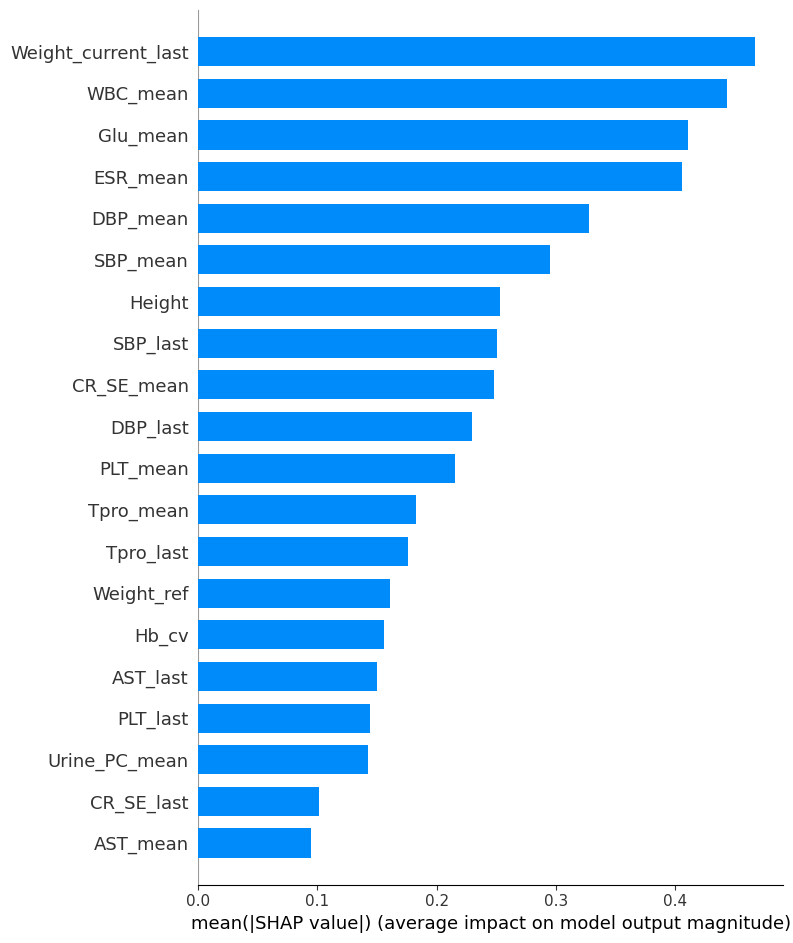

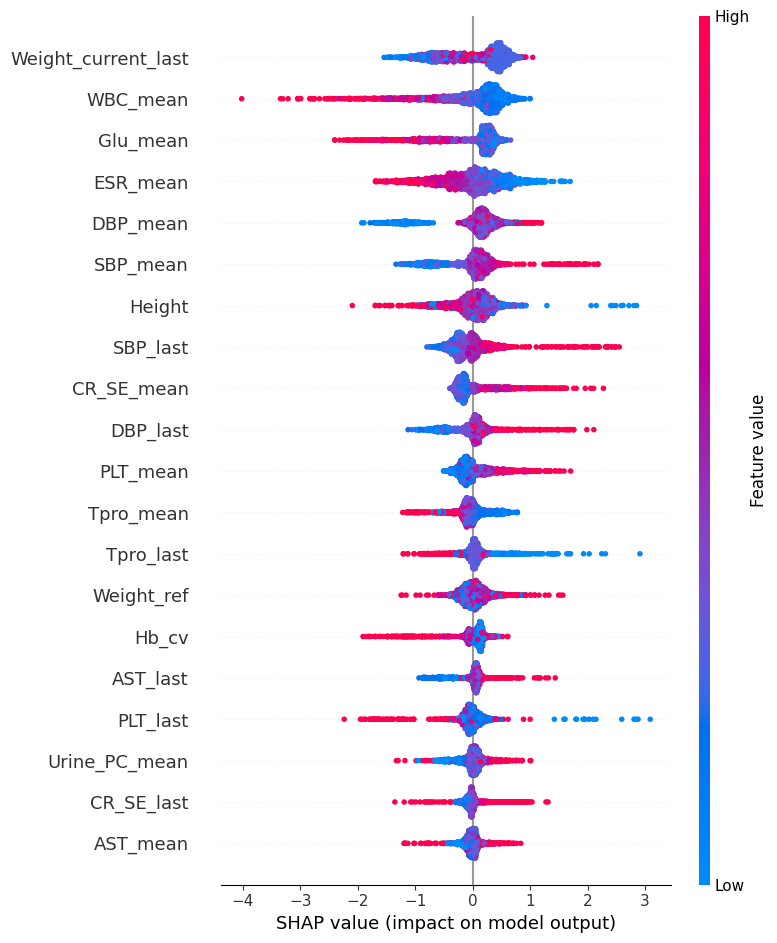

Direction check: compare each feature's colour pattern in the beeswarm with its clinical meaning before writing it up.


In [16]:
# ---------------------------------------------------------------- 15. SHAP (global importance and beeswarm)
if RUN_EXPLAIN and explain_name:
    try:
        import shap
        sv = shap.TreeExplainer(trained[explain_name]).shap_values(Xte_s)
        sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if getattr(sv, 'ndim', 2) == 3 else sv)
        shap_imp = pd.Series(np.abs(sv).mean(0), index=Xte_s.columns).sort_values(ascending=False)
        shap_imp.rename('mean_abs_shap').to_csv(f"{OUT}/table_shap_importance.csv"); print(shap_imp.head(12).round(3))
        plt.figure(); shap.summary_plot(sv, Xte_s, plot_type='bar', show=False, max_display=20); plt.tight_layout(); plt.savefig(f"{OUT}/figs/fig_shap_bar.png", dpi=300, bbox_inches='tight'); plt.show()
        plt.figure(); shap.summary_plot(sv, Xte_s, show=False, max_display=20); plt.tight_layout(); plt.savefig(f"{OUT}/figs/fig_shap_beeswarm.png", dpi=300, bbox_inches='tight'); plt.show()
        print("Direction check: compare each feature's colour pattern in the beeswarm with its clinical meaning before writing it up.")
    except Exception as e:
        print("SHAP skipped:", e)

LIME top-10 Jaccard across 10 seeds: mean 0.60 (min 0.43, max 0.82)
SBP_last                10
DBP_last                10
Hypertension_history    10
SBP_mean                10
CR_SE_mean              10
WBC_mean                 9
Glu_mean                 7
Diabetes_history         6
Prior_preeclampsia       6
D2HYDR01                 4
Family_hypertension      4
PLT_mean                 4
DBP_mean                 2
Height                   2
AST_last                 2
Name: count, dtype: int64


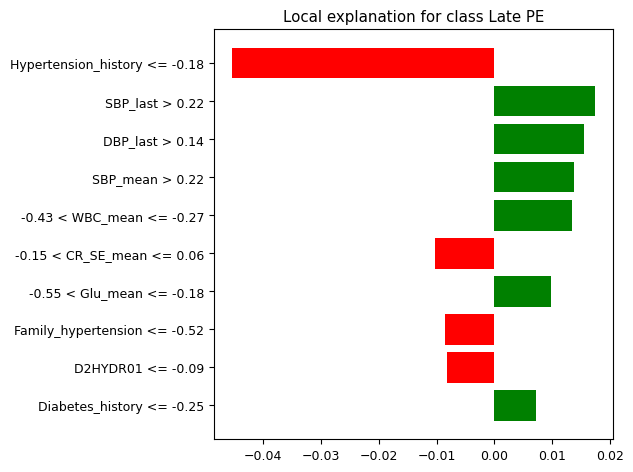

In [17]:
# ---------------------------------------------------------------- 16. LIME stability over 10 seeds (top-10 overlap)
if RUN_EXPLAIN and explain_name:
    try:
        from lime.lime_tabular import LimeTabularExplainer
        x0 = Xte_s.iloc[idx]; tops, weights = [], []
        for s in range(10):
            ex = LimeTabularExplainer(Xtr_s.values, feature_names=list(Xtr_s.columns), class_names=['No PE', 'Late PE'], mode='classification', discretize_continuous=True, random_state=s)
            e = ex.explain_instance(x0.values, trained[explain_name].predict_proba, num_features=10)
            tops.append({Xtr_s.columns[i] for i, _ in e.as_map()[1]}); weights.append(dict(e.as_list()))
        jac = [len(a & b) / len(a | b) for i, a in enumerate(tops) for b in tops[i + 1:]]
        freq = pd.Series([f for t in tops for f in t]).value_counts()
        print(f"LIME top-10 Jaccard across 10 seeds: mean {np.mean(jac):.2f} (min {np.min(jac):.2f}, max {np.max(jac):.2f})"); print(freq.head(15))
        freq.rename('times_in_top10_of_10_seeds').to_csv(f"{OUT}/table_lime_stability.csv")
        e0 = LimeTabularExplainer(Xtr_s.values, feature_names=list(Xtr_s.columns), class_names=['No PE', 'Late PE'], mode='classification', discretize_continuous=True, random_state=0).explain_instance(x0.values, trained[explain_name].predict_proba, num_features=10)
        fig = e0.as_pyplot_figure(); fig.tight_layout(); fig.savefig(f"{OUT}/figs/fig_lime.png", dpi=300); plt.show()
    except Exception as e:
        print("LIME skipped:", e)

In [18]:
# ---------------------------------------------------------------- 17. DiCE counterfactuals: 5 seeds, search limited to training 1st-99th percentile ranges
if RUN_EXPLAIN and explain_name:
    try:
        import dice_ml
        lo, hi = Xtr_s.quantile(0.01), Xtr_s.quantile(0.99)
        d = Xtr_s.copy(); d['late_onset_pe'] = ytr.values
        data = dice_ml.Data(dataframe=d, continuous_features=list(Xtr_s.columns), outcome_name='late_onset_pe')
        model = dice_ml.Model(model=trained[explain_name], backend='sklearn', model_type='classifier')
        runs, changed_sets = [], []
        for s in range(5):
            cf = dice_ml.Dice(data, model, method='random').generate_counterfactuals(
                Xte_s.iloc[[idx]], total_CFs=4, desired_class='opposite', random_seed=s,
                permitted_range={c: [float(lo[c]), float(hi[c])] for c in Xtr_s.columns})
            df_cf = cf.cf_examples_list[0].final_cfs_df
            if df_cf is None or len(df_cf) == 0: changed_sets.append(set()); continue
            diff = (df_cf.drop(columns='late_onset_pe', errors='ignore') != Xte_s.iloc[idx].values).any()
            changed_sets.append(set(diff[diff].index)); runs.append(df_cf)
        print("Features changed per seed:", [sorted(c) for c in changed_sets])
        if runs:
            pd.concat(runs, keys=range(len(runs))).to_csv(f"{OUT}/table_dice_counterfactuals.csv")
        inter = set.intersection(*changed_sets) if changed_sets and all(changed_sets) else set()
        print("Features changed in every seed:", sorted(inter))
    except Exception as e:
        print("DiCE skipped:", e)

DiCE skipped: No module named 'dice_ml'


In [19]:
# ---------------------------------------------------------------- 18. Summary of numbers the manuscript needs
top = res.iloc[0]
print(f"Cohort: {len(X)} women, {int(y.sum())} cases ({y.mean():.1%}); train {len(ytr)}, test {len(yte)} ({int(yte.sum())} cases)")
print(f"Features: {X.shape[1]} candidates -> {len(feats)} selected; trajectory descriptors selected: {sum(f.endswith(('_slope','_cv','_auc')) for f in feats)}")
print(f"Best AUC-ROC: {top['Model']} {top['AUC-ROC']:.3f}; best AUC-PR: {res.sort_values('AUC-PR', ascending=False).iloc[0]['Model']} {res['AUC-PR'].max():.3f}")
print("Highest-accuracy model:", res.sort_values('Accuracy', ascending=False).iloc[0][['Model', 'Accuracy', 'Recall']].to_dict())
print("All files written to:", os.path.abspath(OUT))
print("Next: send the results folder so the manuscript tables, text and figures can be regenerated from these outputs.")

Cohort: 11767 women, 317 cases (2.7%); train 9413, test 2354 (63 cases)
Features: 202 candidates -> 31 selected; trajectory descriptors selected: 1
Best AUC-ROC: Random forest 0.871; best AUC-PR: LightGBM 0.283
Highest-accuracy model: {'Model': 'MLP', 'Accuracy': 0.9745114698385726, 'Recall': 0.30158730158730157}
All files written to: /kaggle/working/results
Next: send the results folder so the manuscript tables, text and figures can be regenerated from these outputs.


In [20]:
!zip -r /kaggle/working/results.zip /kaggle/working/results

  adding: kaggle/working/results/ (stored 0%)
  adding: kaggle/working/results/table_shap_importance.csv (deflated 45%)
  adding: kaggle/working/results/table_selected_features.csv (deflated 43%)
  adding: kaggle/working/results/table_calibration.csv (deflated 58%)
  adding: kaggle/working/results/table_lime_stability.csv (deflated 37%)
  adding: kaggle/working/results/test_predictions.csv (deflated 56%)
  adding: kaggle/working/results/table_cohort.csv (deflated 6%)
  adding: kaggle/working/results/table_test_performance.csv (deflated 56%)
  adding: kaggle/working/results/figs/ (stored 0%)
  adding: kaggle/working/results/figs/fig_shap_bar.png (deflated 28%)
  adding: kaggle/working/results/figs/fig_shap_beeswarm.png (deflated 6%)
  adding: kaggle/working/results/figs/fig_lime.png (deflated 23%)
  adding: kaggle/working/results/figs/fig_confusion_top.png (deflated 26%)
  adding: kaggle/working/results/figs/fig_calibration.png (deflated 16%)
  adding: kaggle/working/results/figs/fig_ro

In [21]:
from IPython.display import FileLink

FileLink('results.zip')


/kaggle/working/results.zip